# Hospital infection control: can earlier transfers help predict later clusters?

Choose **this option or the power-network option**, not both. This small, synthetic dataset describes wards and transfers in a regional hospital group. Each ward is a node. Transfers observed **before** the prediction point are directed, weighted links. At that point some wards already have active clusters. Predict a **new** simulated cluster during the next 14 days only among wards without an active cluster.

Work through Part 1 (data and EDA), Part 2 (network), and Part 3 (comparison). Most code is provided. Replace six obvious `___` markers using the hints beside them, then complete the short written responses. Keep code, plots and short answers visible when you submit the notebook. No information from `new_cluster_later` may enter a model feature.


## Portfolio summary

- **Author:** Maria-Gavriela Andreou (GitHub: marielandreou)
- **Course:** Complex Systems and Applications, final project
- **Option chosen:** Option 1, Hospital infection control
- **Data:** `hospital_wards.csv` and `hospital_transfers.csv` (synthetic course data, loaded from `https://raw.githubusercontent.com/mikeauth/leap/main/hospital`)
- **How to run:** *Kernel → Restart & Run All.* It needs internet access, or both CSVs placed beside this notebook.
- **Outline:** Part 1, data and EDA · Part 2, directed network · Part 3, required model comparison · Part 4, extension (robustness, ablation, placebo controls, errors and thresholds) · Final interpretation · Reflection

**Question.** Among the 102 wards without an active cluster, do directed transfers from the previous 14 days help predict a new simulated cluster in the next 14 days, beyond occupancy and device use?

**Approach.** I built a directed, weighted transfer network (120 wards, 420 links) and computed each ward's total incoming transfer volume and the volume received from the 18 wards already active. Two logistic regressions, with and without these features, were trained and tested on the same stratified 70/30 split, with scaling fitted on training rows only.

**Result.** Yes, on this test set: F1 rose from 0.435 to 0.737 and ROC AUC from 0.693 to 0.904, and false alarms fell from 6 to 0, although 5 of 12 clusters were still missed. Repeated cross-validation and two placebo checks support the gain.

**Main limitation.** The data are synthetic and small. A transfer link is not an infection route, and a better score shows neither causation nor fitness for clinical decisions.


## Part 1: load the prepared data and explore it

The two CSVs have already been constructed. The notebook downloads them from their published course URLs; if the address is temporarily unavailable, put both provided CSVs beside this notebook. `occupancy_ratio` and `device_use_share` are known before the follow-up period. The later outcome is blank for wards already affected at the prediction point.


In [1]:
DATA_BASE_URL = 'https://raw.githubusercontent.com/mikeauth/leap/main/hospital'
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, ConfusionMatrixDisplay

SEED = 123

def load_course_csv(filename):
    # The course address is the folder containing the prepared CSVs. For offline work, keep a
    # downloaded CSV in the same folder as this notebook.
    url = f'{DATA_BASE_URL}/{filename}'
    try:
        return pd.read_csv(url)
    except Exception:
        local = Path(filename)
        if local.is_file():
            print(f'Using local copy of {filename}; course URL was unavailable.')
            return pd.read_csv(local)
        raise FileNotFoundError(f'Cannot read {url}. Download {filename} next to the notebook or ask for the course URL.')

wards = load_course_csv('hospital_wards.csv')
transfers = load_course_csv('hospital_transfers.csv')
assert wards['ward_id'].is_unique
assert {'ward_id','occupancy_ratio','device_use_share','active_cluster_at_start','new_cluster_later'} <= set(wards)
assert {'source_ward_id','destination_ward_id','transfer_count'} <= set(transfers)
display(wards.head())
display(transfers.head())
print('Wards:',len(wards),'Directed links:',len(transfers))


,ward_id,occupancy_ratio,device_use_share,active_cluster_at_start,new_cluster_later
0,W001,0.758,0.187,1,NaN
1,W002,0.886,0.338,0,1.0
2,W003,0.533,0.197,0,0.0
3,W004,0.777,0.364,0,1.0
4,W005,0.775,0.446,0,1.0


,source_ward_id,destination_ward_id,transfer_count
0,W001,W006,4
1,W001,W042,6
2,W001,W093,9
3,W001,W111,5
4,W002,W050,3


Wards: 120 Directed links: 420


### Focused EDA: follow the worked code

Exclude wards already affected at the observation point. Count eligible wards and the two later classes. Show one bar chart of the later outcome and two boxplots comparing the original ward attributes by later outcome. In two or three sentences, say whether the groups overlap. Looking at labels for EDA is acceptable; do not use later labels to create predictors.


Eligible: 102 Later clusters: 39


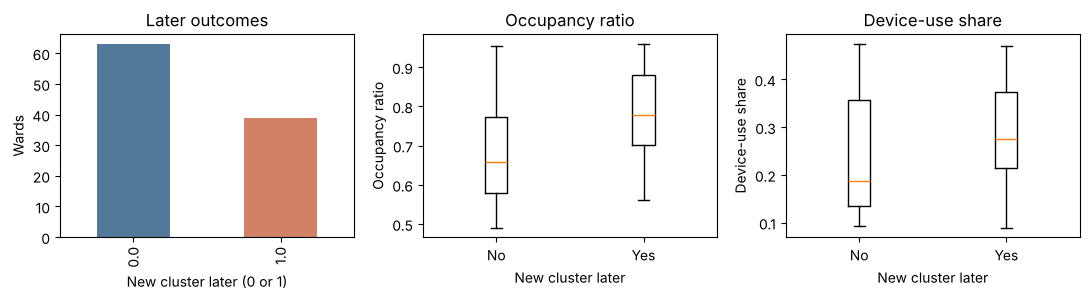

In [2]:
# TODO 1: Fill in the starting-status value for eligible wards.
# Hint: wards['active_cluster_at_start'].eq(0)
eligible_eda = wards.loc[wards['active_cluster_at_start'].eq(0)].copy()
assert eligible_eda['new_cluster_later'].notna().all()
counts = eligible_eda['new_cluster_later'].value_counts().reindex([0.,1.],fill_value=0)
print('Eligible:',len(eligible_eda),'Later clusters:',int(counts.loc[1.]))
fig, axes = plt.subplots(1,3,figsize=(11,3.1))
counts.plot.bar(ax=axes[0],color=['#53799a','#d18166'])
axes[0].set(xlabel='New cluster later (0 or 1)',ylabel='Wards',title='Later outcomes')
for ax,column,label in zip(axes[1:],['occupancy_ratio','device_use_share'],['Occupancy ratio','Device-use share']):
    groups=[eligible_eda.loc[eligible_eda['new_cluster_later'].eq(k),column] for k in [0,1]]
    ax.boxplot(groups,tick_labels=['No','Yes'])
    ax.set(xlabel='New cluster later',ylabel=label,title=label)
plt.tight_layout();plt.show()


**Write here:** How many wards are eligible? Do their starting attributes separate the later classes cleanly? (Two or three sentences.)

**Answer.** 102 of the 120 wards are eligible (18 already had a cluster), and 39 of them (38%) later had a new cluster. Wards with a later cluster tend to have higher occupancy (median 0.78 vs 0.66) and somewhat higher device use (median 0.28 vs 0.19). However, the boxes overlap, almost completely for device use, and the full ranges nearly coincide (occupancy 0.49–0.95 for "No" vs 0.56–0.96 for "Yes"), so neither attribute separates the classes cleanly.


## Part 2: directed transfer network

A row in `hospital_transfers.csv` means transfers **from** `source_ward_id` **to** `destination_ward_id` in the 14 days before prediction. Use a directed graph and attach `transfer_count` as the link weight. Add all wards first, including isolated wards. Calculate each ward's incoming transfer volume, then the volume received from wards with a cluster **already active** at the prediction point. These use the known initial status, never later labels.


In [3]:
G = nx.DiGraph()
G.add_nodes_from(wards['ward_id'])
valid = set(wards['ward_id'])
assert transfers['source_ward_id'].isin(valid).all() and transfers['destination_ward_id'].isin(valid).all()
assert (transfers['source_ward_id'] != transfers['destination_ward_id']).all()
assert not transfers.duplicated(['source_ward_id','destination_ward_id']).any()
for row in transfers.itertuples(index=False):
    # TODO 2: Supply the number of transfers as the link weight.
    # Hint: transfer_count=int(row.transfer_count)
    G.add_edge(row.source_ward_id,row.destination_ward_id,transfer_count=int(row.transfer_count))
initial = wards.set_index('ward_id')['active_cluster_at_start']
# TODO 3: Select sources with a cluster already active at the start.
# Hint: initial.loc[src] == 1
wards['incoming_volume'] = [G.in_degree(i,weight='transfer_count') for i in wards['ward_id']]
wards['from_active_volume'] = [sum(d['transfer_count'] for src,_,d in G.in_edges(i,data=True)
                                    if initial.loc[src] == 1) for i in wards['ward_id']]
print('Nodes:',G.number_of_nodes(),'Directed links:',G.number_of_edges())
display(wards[['ward_id','incoming_volume','from_active_volume']].head())
assert (wards['from_active_volume'] <= wards['incoming_volume']).all()


Nodes: 120 Directed links: 420


,ward_id,incoming_volume,from_active_volume
0,W001,19,0
1,W002,42,15
2,W003,14,3
3,W004,30,0
4,W005,8,0


### Visualise and interpret the network

Make one readable illustration using about 35 wards with the largest incoming volume. Colour nodes by **initial** cluster status; do not colour them by later outcomes. A plotted subset is for illustration only: **use all wards and all links** for feature calculations. Plot a histogram of `from_active_volume` among eligible wards. Write what a high value means and why edge direction matters.


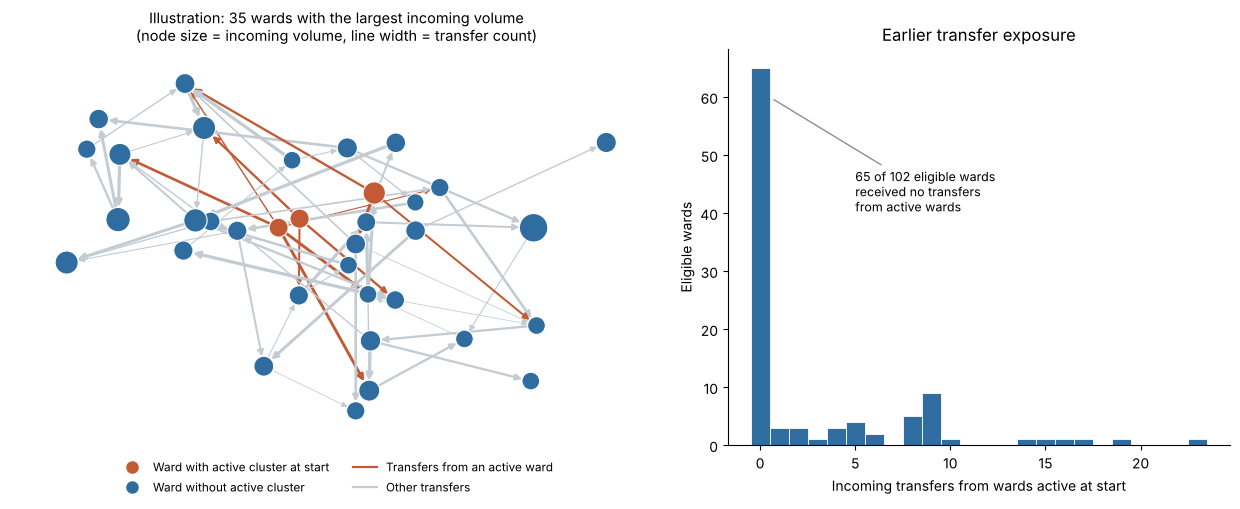

In [4]:
shown=wards.nlargest(35,'incoming_volume')['ward_id'].tolist()
small=G.subgraph(shown)
from matplotlib.lines import Line2D
ACTIVE, OTHER, EDGE = '#c25a35', '#2f6da0', '#c3ccd3'
in_vol = wards.set_index('ward_id')['incoming_volume']
sizes = [25 + 6 * in_vol.loc[i] for i in small.nodes]   # node size = incoming volume (all links)
fig,axes=plt.subplots(1,2,figsize=(12.5,5.2),gridspec_kw={'width_ratios':[1.3,1]})
pos=nx.spring_layout(small,seed=42,k=.6)
# Colour uses the INITIAL status only: highlighted links leave a ward that was active at the start.
nx.draw_networkx_edges(small,pos,ax=axes[0],node_size=sizes,arrows=True,arrowstyle='-|>',arrowsize=9,
    width=[.35 + .22 * d['transfer_count'] for _,_,d in small.edges(data=True)],
    edge_color=[ACTIVE if initial.loc[u]==1 else EDGE for u,_ in small.edges])
nx.draw_networkx_nodes(small,pos,ax=axes[0],node_size=sizes,edgecolors='white',linewidths=.8,
    node_color=[ACTIVE if initial.loc[i]==1 else OTHER for i in small.nodes])
axes[0].legend(handles=[
    Line2D([],[],marker='o',ls='',color=ACTIVE,ms=8,label='Ward with active cluster at start'),
    Line2D([],[],marker='o',ls='',color=OTHER,ms=8,label='Ward without active cluster'),
    Line2D([],[],color=ACTIVE,lw=1.6,label='Transfers from an active ward'),
    Line2D([],[],color=EDGE,lw=1.6,label='Other transfers')],
    loc='upper center',bbox_to_anchor=(.5,-.01),ncol=2,frameon=False,fontsize=8.5)
axes[0].set_title('Illustration: 35 wards with the largest incoming volume\n(node size = incoming volume, line width = transfer count)',fontsize=10.5)
axes[0].set_axis_off()
exposure=wards.loc[wards['active_cluster_at_start'].eq(0),'from_active_volume']
axes[1].hist(exposure,bins=np.arange(-.5,exposure.max()+1.5,1),color=OTHER,edgecolor='white',linewidth=.6)
none=int(exposure.eq(0).sum())
axes[1].annotate(f'{none} of {len(exposure)} eligible wards\nreceived no transfers\nfrom active wards',
    xy=(.6,none*.92),xytext=(5,none*.62),fontsize=9,arrowprops=dict(arrowstyle='-',color='#8a8f96'))
axes[1].set(xlabel='Incoming transfers from wards active at start',ylabel='Eligible wards',title='Earlier transfer exposure')
axes[1].spines[['top','right']].set_visible(False)
plt.tight_layout();plt.show()


**Write here:** What does high `from_active_volume` mean? Why is it different from outgoing transfers? (Two sentences.)

**Answer.** A high `from_active_volume` means the ward received many patients in the previous 14 days from wards that already had an active cluster, so it measures the ward's recorded exposure to the affected part of the network (65 of the 102 eligible wards received none). Direction matters because a transfer from ward X to ward Y moves patients *into* Y, so incoming links describe what arrives at a ward while outgoing transfers only describe what it sends elsewhere; Part 4 confirms that the reversed measure, volume *sent to* active wards, adds almost nothing.


## Part 3: compare logistic regression fairly

Only wards without an active cluster are eligible. Model A uses `occupancy_ratio` and `device_use_share`. Model B adds `incoming_volume` and `from_active_volume`. Use the **same wards and the same stratified train/test split**. Fit each scaler inside a pipeline trained only on training rows. Compare accuracy, F1 for later clusters, ROC AUC from probabilities, and both confusion matrices. With a small fixed sample, different scores can move in different directions.


,Accuracy,F1,ROC AUC
Original ward features,0.581,0.435,0.693
Ward + network features,0.839,0.737,0.904


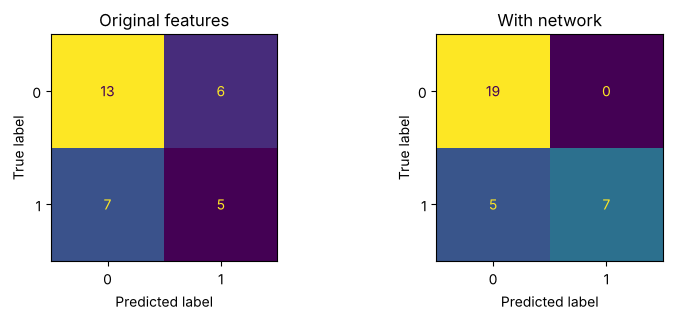

In [5]:
eligible = wards.loc[wards['active_cluster_at_start'].eq(0)].set_index('ward_id').copy()
y = eligible['new_cluster_later'].astype(int)
# TODO 4: Set aside 30% of eligible observations for testing.
# Hint: test_size=.30
train_ids,test_ids = train_test_split(y.index,test_size=.30,stratify=y,random_state=SEED)
original=['occupancy_ratio','device_use_share']
# TODO 5: Add the measure of transfers from wards active at the start.
# Hint: with_network = original + ['incoming_volume', 'from_active_volume']
with_network=original+['incoming_volume','from_active_volume']

def fit_and_score(columns):
    model=make_pipeline(StandardScaler(),LogisticRegression(max_iter=1000))
    model.fit(eligible.loc[train_ids,columns],y.loc[train_ids])
    predicted=model.predict(eligible.loc[test_ids,columns])
    probabilities=model.predict_proba(eligible.loc[test_ids,columns])[:,1]
    scores={'Accuracy':accuracy_score(y.loc[test_ids],predicted),
            'F1':f1_score(y.loc[test_ids],predicted,zero_division=0),
            # TODO 6: Use the predicted probability for ROC AUC.
            # Hint: roc_auc_score(y.loc[test_ids], probabilities)
            'ROC AUC':roc_auc_score(y.loc[test_ids],probabilities)}
    return scores,predicted

base_scores,base_pred=fit_and_score(original)
network_scores,network_pred=fit_and_score(with_network)
results=pd.DataFrame([base_scores,network_scores],index=['Original ward features','Ward + network features'])
display(results.round(3))
fig,axes=plt.subplots(1,2,figsize=(8,3.3))
for ax,pred,title in zip(axes,[base_pred,network_pred],['Original features','With network']):
    ConfusionMatrixDisplay.from_predictions(y.loc[test_ids],pred,ax=ax,labels=[0,1],colorbar=False)
    ax.set_title(title)
plt.tight_layout();plt.show()


## Part 4 (extension): is the gain robust, and where does it come from?

The required comparison in Part 3 is the headline answer, and nothing below replaces it. The test set has only 31 wards, 12 of which later had a cluster, so a single ward changing class moves F1 by about 0.06. To check that the result is not an accident of one split, I added four checks. As in Part 3, `new_cluster_later` is used only as the target and never to build a feature.

1. **Repeated cross-validation.** Stratified 5-fold CV repeated 20 times gives 100 paired train/test evaluations on the same 102 wards. The scaler and model are refitted inside every training fold.
2. **Ablation.** Each network feature is added on its own to see which one carries the signal.
3. **Two placebo controls.**
   - *Direction reversed:* the volume a ward **sent to** active wards, computed from the same graph and the same initial status. If edge direction did not matter, this should help as much as `from_active_volume`.
   - *Shuffled:* the two network features are randomly permuted across wards. This keeps their distribution but breaks the link to each ward. Any gain here would mean the improvement came from simply adding columns.
4. **Error and threshold analysis** of the clusters the network model missed (4b and 4c).


,Mean ROC AUC,SD ROC AUC,Mean F1,Mean AUC gain vs A,Share of folds beating A
model,,,,,
A: ward attributes only,0.720,0.099,0.533,NaN,NaN
A + incoming volume,0.862,0.084,0.730,0.142,0.96
A + volume from active wards,0.864,0.077,0.698,0.144,1.00
B: A + both network features,0.895,0.072,0.722,0.175,0.98
Placebo: A + volume sent to active wards,0.739,0.100,0.536,0.019,0.59
Placebo: A + shuffled network features,0.708,0.105,0.512,-0.013,0.34


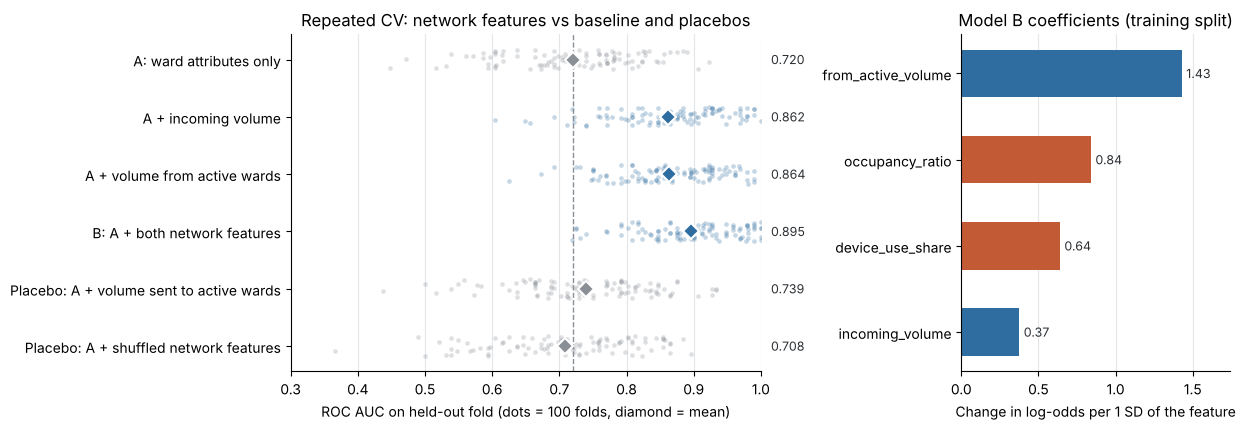

In [6]:
# Part 4a: repeated cross-validation, ablation and placebo controls.
from sklearn.base import clone
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict

pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
network_cols = ['incoming_volume', 'from_active_volume']

# Direction placebo: transfers SENT TO wards active at the start (out-edges). It uses only the
# earlier graph and the initial status, never later labels.
eligible['to_active_volume'] = pd.Series(
    {i: sum(d['transfer_count'] for _, dst, d in G.out_edges(i, data=True) if initial.loc[dst] == 1)
     for i in eligible.index})

feature_sets = {
    'A: ward attributes only': original,
    'A + incoming volume': original + ['incoming_volume'],
    'A + volume from active wards': original + ['from_active_volume'],
    'B: A + both network features': with_network,
    'Placebo: A + volume sent to active wards': original + ['to_active_volume'],
    'Placebo: A + shuffled network features': with_network,  # columns permuted in each fold
}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=20, random_state=SEED)
rng = np.random.default_rng(SEED)
rows = []
for fold, (tr, te) in enumerate(cv.split(eligible, y)):
    shuffled = eligible.copy()
    shuffled[network_cols] = shuffled[network_cols].to_numpy()[rng.permutation(len(shuffled))]
    for name, cols in feature_sets.items():
        X = shuffled if 'shuffled' in name else eligible
        fitted = clone(pipe).fit(X.iloc[tr][cols], y.iloc[tr])
        prob = fitted.predict_proba(X.iloc[te][cols])[:, 1]
        rows.append({'fold': fold, 'model': name,
                     'ROC AUC': roc_auc_score(y.iloc[te], prob),
                     'F1': f1_score(y.iloc[te], (prob >= .5).astype(int), zero_division=0)})
cv_results = pd.DataFrame(rows)

base_name = 'A: ward attributes only'
wide = cv_results.pivot(index='fold', columns='model', values='ROC AUC')
cv_summary = cv_results.groupby('model', sort=False).agg(
    **{'Mean ROC AUC': ('ROC AUC', 'mean'), 'SD ROC AUC': ('ROC AUC', 'std'), 'Mean F1': ('F1', 'mean')})
cv_summary['Mean AUC gain vs A'] = wide.sub(wide[base_name], axis=0).mean()
cv_summary['Share of folds beating A'] = wide.gt(wide[base_name], axis=0).mean()
cv_summary.loc[base_name, ['Mean AUC gain vs A', 'Share of folds beating A']] = np.nan
display(cv_summary.round(3))

# Refit the two Part 3 models on the same training rows (identical to fit_and_score) so they can be inspected.
model_A = clone(pipe).fit(eligible.loc[train_ids, original], y.loc[train_ids])
model_B = clone(pipe).fit(eligible.loc[train_ids, with_network], y.loc[train_ids])
coefs = pd.Series(model_B[-1].coef_[0], index=with_network)

BLUE, ORANGE, GREY, INK = '#2f6da0', '#c25a35', '#8a8f96', '#2b2f33'
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4), gridspec_kw={'width_ratios': [1.75, 1]})
ax = axes[0]
names = list(feature_sets)[::-1]
for k, name in enumerate(names):
    vals = cv_results.loc[cv_results['model'].eq(name), 'ROC AUC'].to_numpy()
    colour = GREY if (name == base_name or name.startswith('Placebo')) else BLUE
    jitter = np.random.default_rng(k).uniform(-.17, .17, len(vals))
    ax.scatter(vals, k + jitter, s=11, alpha=.28, color=colour, linewidths=0)
    ax.plot(vals.mean(), k, marker='D', ms=8, color=colour, mec='white', mew=1.5, zorder=3)
    ax.text(1.015, k, f'{vals.mean():.3f}', va='center', fontsize=9, color=INK)
ax.axvline(wide[base_name].mean(), color=GREY, ls='--', lw=1)
ax.set_yticks(range(len(names)), names)
ax.set_xlim(.3, 1.0)
ax.set(xlabel='ROC AUC on held-out fold (dots = 100 folds, diamond = mean)',
       title='Repeated CV: network features vs baseline and placebos')
ax = axes[1]
order = coefs.sort_values().index
ax.barh(range(len(order)), coefs[order], height=.55,
        color=[BLUE if c in network_cols else ORANGE for c in order])
for k, c in enumerate(order):
    ax.text(coefs[c] + .03, k, f'{coefs[c]:.2f}', va='center', fontsize=9, color=INK)
ax.set_yticks(range(len(order)), order)
ax.set_xlim(0, coefs.max() * 1.22)
ax.set(xlabel='Change in log-odds per 1 SD of the feature', title='Model B coefficients (training split)')
for a in axes:
    a.spines[['top', 'right']].set_visible(False)
    a.grid(axis='x', color='#e3e6e9', lw=.8)
    a.set_axisbelow(True)
plt.tight_layout(); plt.show()


**What 4a shows.**

- **The gain is robust.** Model B averages ROC AUC 0.895 against 0.720 for Model A, a gain of +0.175, and it beats A in 98 of 100 paired folds. Its F1 averages 0.722 against 0.533. The single-split gain in Part 3 (+0.21 AUC) is slightly larger than average, which is expected from a 31-ward test set, but it points the same way. Because the folds reuse the same 102 wards, this is a stability check, not a formal significance test.
- **Both features help, and they overlap.** Each one alone adds about +0.14 AUC, and together they add +0.175. The features are correlated (r ≈ 0.59 among eligible wards), because a ward that receives many transfers is also more likely to receive some from active wards. In Model B, `from_active_volume` has by far the largest coefficient (1.43 vs 0.37 for `incoming_volume`).
- **Direction matters.** Reversing the edges (volume *sent to* active wards) adds only +0.02 AUC and beats A in 59% of folds, about the rate of a coin flip. What predicts a cluster is what a ward receives, not what it sends.
- **The gain is not an artefact of adding columns.** With the network features shuffled across wards, AUC falls slightly below A (−0.01, beating A in only 34% of folds).

These are associations in synthetic data. The published construction rule gives exposure to active wards the largest weight (0.86), then occupancy (0.62), device use (0.54) and incoming volume (0.24). Model B's coefficients (1.43, 0.84, 0.64, 0.37) rank the four features in exactly the same order. The checks therefore show that the model recovers a signal that was deliberately placed in the data, which is a useful sanity test, not a discovery about real hospitals.


### 4b: which clusters does the network model miss?

The final interpretation asks about errors. Below are the 12 test wards that later had a cluster, sorted by Model B's predicted probability, along with both models' probabilities (≥ 0.5 counts as flagged).


In [7]:
test_view = eligible.loc[test_ids, with_network].copy()
test_view['p_A'] = model_A.predict_proba(eligible.loc[test_ids, original])[:, 1]
test_view['p_B'] = model_B.predict_proba(eligible.loc[test_ids, with_network])[:, 1]
later = test_view[y.loc[test_ids].eq(1)].sort_values('p_B').copy()
later['Model A'] = np.where(later['p_A'] >= .5, 'caught', 'missed')
later['Model B'] = np.where(later['p_B'] >= .5, 'caught', 'missed')
display(later.round(2))
print('Median from_active_volume of clusters Model B missed:',
      later.loc[later['Model B'].eq('missed'), 'from_active_volume'].median(),
      '| caught:', later.loc[later['Model B'].eq('caught'), 'from_active_volume'].median())


,occupancy_ratio,device_use_share,incoming_volume,from_active_volume,p_A,p_B,Model A,Model B
ward_id,,,,,,,,
W030,0.75,0.11,25,0,0.23,0.15,missed,missed
W071,0.58,0.14,43,2,0.13,0.18,missed,missed
W099,0.72,0.33,28,0,0.46,0.33,missed,missed
W070,0.70,0.24,12,5,0.32,0.38,missed,missed
W004,0.78,0.36,30,0,0.58,0.48,caught,missed
W011,0.95,0.41,13,0,0.81,0.65,caught,caught
W009,0.72,0.31,26,6,0.44,0.68,missed,caught
W054,0.95,0.32,47,0,0.71,0.78,caught,caught
W110,0.83,0.22,12,9,0.46,0.79,missed,caught


Median from_active_volume of clusters Model B missed: 0.0 | caught: 8.0


**What 4b shows.** The five clusters Model B missed were all in wards with little or no recorded exposure: three received no transfers from active wards and the other two received 2 and 5. The clusters it caught had a median exposure of 8. Two caught wards had zero exposure but very high occupancy (0.95), and one of them also had the largest incoming volume in the test set (47). One miss, W004, had actually been caught by Model A (0.58) but fell just below the threshold in Model B (0.48), because its lack of exposure lowered its score. So the network model is better on average, not on every ward. The model therefore mostly finds clusters along the transfer paths from affected wards. A cluster that arises without that recorded exposure looks like an ordinary ward to it. This is a systematic blind spot rather than random noise, and it matters for the ethics question: wards outside the main transfer routes would be under-flagged.


### 4c: trading missed clusters against false alarms

At the default threshold of 0.5, Model B raised no false alarms but missed 5 of 12 clusters. In infection control a miss is usually costlier than a false alarm, but where to set the threshold is a policy choice. To show the trade-off without tuning on the test set, I chose the threshold using **training wards only**: 5-fold out-of-fold predictions on the 71 training wards, keeping the threshold with the highest out-of-fold F1. I then applied it to the test set once.


Threshold chosen on training folds only: 0.25  (out-of-fold F1 0.769)
Test set, threshold default 0.50: F1 0.737, missed 5 of 12, false alarms 0 of 19
Test set, threshold chosen 0.25: F1 0.769, missed 2 of 12, false alarms 4 of 19


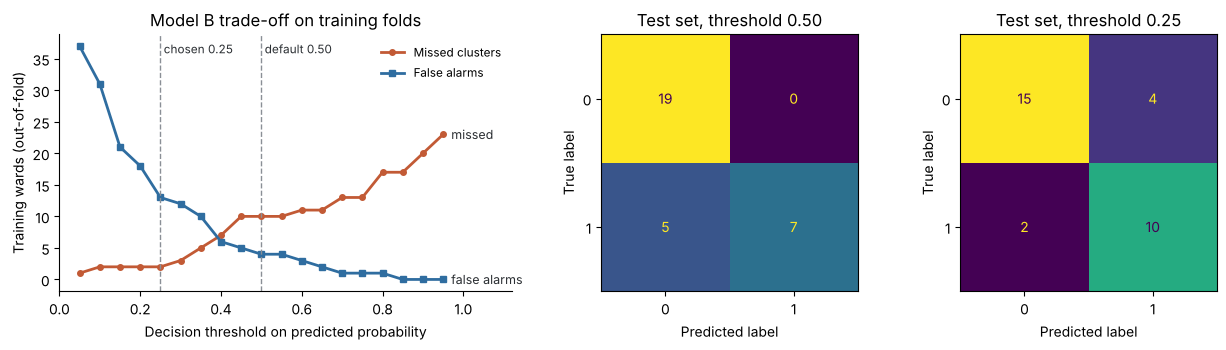

In [8]:
y_tr = y.loc[train_ids]
oof = cross_val_predict(clone(pipe), eligible.loc[train_ids, with_network], y_tr,
                        cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method='predict_proba')[:, 1]
thresholds = np.round(np.arange(.05, .96, .05), 2)
missed = [int(((oof < t) & (y_tr == 1)).sum()) for t in thresholds]
false_alarms = [int(((oof >= t) & (y_tr == 0)).sum()) for t in thresholds]
oof_f1 = [f1_score(y_tr, (oof >= t).astype(int), zero_division=0) for t in thresholds]
chosen = float(thresholds[int(np.argmax(oof_f1))])
print(f'Threshold chosen on training folds only: {chosen:.2f}  (out-of-fold F1 {max(oof_f1):.3f})')

p_test = test_view['p_B']
y_te = y.loc[test_ids]
for label, t in [('default 0.50', .5), (f'chosen {chosen:.2f}', chosen)]:
    pred = (p_test >= t).astype(int)
    print(f'Test set, threshold {label}: F1 {f1_score(y_te, pred):.3f}, '
          f'missed {int(((pred == 0) & (y_te == 1)).sum())} of {int(y_te.sum())}, '
          f'false alarms {int(((pred == 1) & (y_te == 0)).sum())} of {int((y_te == 0).sum())}')

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.6), gridspec_kw={'width_ratios': [1.6, 1, 1]})
ax = axes[0]
ax.plot(thresholds, missed, color=ORANGE, lw=2, marker='o', ms=4, label='Missed clusters')
ax.plot(thresholds, false_alarms, color=BLUE, lw=2, marker='s', ms=4, label='False alarms')
ax.text(thresholds[-1] + .02, missed[-1], 'missed', va='center', fontsize=9, color=INK)
ax.text(thresholds[-1] + .02, false_alarms[-1], 'false alarms', va='center', fontsize=9, color=INK)
for t, txt in [(.5, 'default'), (chosen, 'chosen')]:
    ax.axvline(t, color=GREY, ls='--', lw=1)
    ax.text(t, ax.get_ylim()[1] * .97, f' {txt} {t:.2f}', fontsize=8.5, color=INK, va='top')
ax.set_xlim(0, 1.12)
ax.set(xlabel='Decision threshold on predicted probability',
       ylabel='Training wards (out-of-fold)', title='Model B trade-off on training folds')
ax.legend(frameon=False, loc='upper right', fontsize=8.5)
ax.spines[['top', 'right']].set_visible(False)
for ax, t in zip(axes[1:], [.5, chosen]):
    ConfusionMatrixDisplay.from_predictions(y_te, (p_test >= t).astype(int), ax=ax, labels=[0, 1], colorbar=False)
    ax.set_title(f'Test set, threshold {t:.2f}')
plt.tight_layout(); plt.show()


**What 4c shows.** The threshold chosen on the training folds was 0.25. On the test set it would have reduced missed clusters from 5 to 2 at the cost of 4 false alarms, and F1 would have risen from 0.737 to 0.769. This does not make a "better model". It is the same model with a different balance of errors. Which balance is acceptable depends on the cost of an unnecessary screening round compared with an undetected cluster. That decision belongs to the infection-prevention team, not to the metric.


### Final interpretation and portfolio summary

*Prompt: 100–180 words. Answer the question, compare F1 and ROC AUC, describe an error, distinguish the two network features, and consider the ethics.*

**Did adding earlier directed transfers help predict new clusters on this test set? Yes.** On the same 31 test wards, F1 rose from 0.435 to 0.737, ROC AUC from 0.693 to 0.904, and accuracy from 0.581 to 0.839. All three metrics agree, so the result is not mixed. Model A raised 6 false alarms and missed 7 of 12 clusters. Model B raised none but still missed 5, mostly wards with no recorded exposure. Total incoming volume measures how many patients a ward receives from anywhere. Volume from initially affected wards counts only patients arriving from wards that already had a cluster, and it carried the larger coefficient. If predictions guided infection-control attention, a false alarm could divert screening, isolation beds and staff time and worry patients. A missed cluster could leave patients and staff unprotected. The infection-prevention team and ward clinicians should review flags before acting and audit misses across ward types. Finally, a transfer link is not an infection route, and synthetic scores cannot show causation or clinical usefulness.


## Reflection

**What worked well.** The pipeline design made the comparison fair by construction: both models share one split, and scaling is learned only from training rows. The placebo controls were the most useful addition. They turned "the score went up" into "the gain depends on *who sent* the patients, not on adding more columns".

**What was difficult.** With only 31 test wards, one ward changing class moves F1 by about 0.06, so a single split can overstate or understate a difference. Repeated cross-validation was needed to judge the size of the gain. Timing also needed constant care: every feature, including the placebo, had to use only the initial status and the earlier transfers, never later labels.

**What I would improve with more time.**
- Use a time-ordered validation (train on one period, test on the next) instead of random splits.
- Try exposure measures that follow longer transfer chains, such as two-step paths or a PageRank-style score.
- Calibrate the predicted probabilities before using them to rank wards.
- For any real use, validate on independent hospital data together with clinicians.
